# Notebook 01: IEEE-CIS Dataset Exploration and XGBoost Baseline

This notebook loads the **IEEE-CIS Fraud Detection** dataset, constructs proxy `User` and `Card` identifiers, maps features to the TabFormer schema, creates temporal train/val/test splits, and trains a GPU-accelerated **XGBoost baseline** for fraud detection.

**Primary metric**: Average Precision (AUPRC).

## Outline

0. Setup and Imports
1. Load Raw IEEE-CIS Dataset
2. Preprocessing & Feature Mapping
3. Temporal Split
4. XGBoost Baseline
5. Conclusion

---
## 0. Setup and Imports

In [7]:
!pip install -q "xgboost>=3.0" scikit-learn pandas matplotlib seaborn

In [8]:
import time
import random
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import cudf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import roc_auc_score, average_precision_score

import xgboost as xgb
import torch

print(f"cuDF version:    {cudf.__version__}")
print(f"XGBoost version: {xgb.__version__}")
print(f"GPU available:   {torch.cuda.is_available()}")
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f"GPU 0:           {props.name}, {props.total_memory / 1e9:.1f} GB")

XGB_DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

cuDF version:    24.08.03
XGBoost version: 3.2.0
GPU available:   True
GPU 0:           NVIDIA A100 80GB PCIe, 85.1 GB


In [9]:
PROJECT_ROOT = Path(".").resolve()
DATA_IEEE_DIR = PROJECT_ROOT / "data_ieee"
TEMPORAL_SPLIT_DIR = DATA_IEEE_DIR / "temporal_split"

# Raw files
TRAIN_TRANS = DATA_IEEE_DIR / "train_transaction.csv"
TRAIN_ID = DATA_IEEE_DIR / "train_identity.csv"
TEST_TRANS = DATA_IEEE_DIR / "test_transaction.csv"
TEST_ID = DATA_IEEE_DIR / "test_identity.csv"

EVAL_SAMPLES = 100_000
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

---
## 1. Load Raw IEEE-CIS Dataset

We load the train and test transaction and identity files, then merge them. Note that test set does not have `isFraud` column, so we will use it later for inference or just split train into train/val/test temporally. 

In [10]:
print("Loading train transactions and identity...")
t0 = time.time()
train_tx = cudf.read_csv(str(TRAIN_TRANS))
train_id = cudf.read_csv(str(TRAIN_ID))
raw_gdf = train_tx.merge(train_id, on='TransactionID', how='left')
print(f"cuDF load & merge time: {time.time() - t0:.2f}s")
print(f"Shape: {raw_gdf.shape[0]:,} rows x {raw_gdf.shape[1]} columns")

Loading train transactions and identity...
cuDF load & merge time: 3.64s
Shape: 590,540 rows x 434 columns


---
## 2. Preprocessing & Feature Mapping

We need to map IEEE-CIS features to the expected TabFormer schema:

| TabFormer Column | IEEE-CIS Mapping | Notes |
| :--- | :--- | :--- |
| `User` | Label-encoded `User_ID` | Group of `card1-card5` + `addr1` + `addr2` + `P_emaildomain` |
| `Card` | Label-encoded `Card_ID` | Group of `card1-card5` |
| `Amount` | `TransactionAmt` | Formatted as string (e.g. `"$10.50"`) |
| `Use Chip` | `ProductCD` | Mapped directly to values |
| `Merchant Name` | `card1` | Numeric proxy |
| `Merchant City` | `P_emaildomain` | Domain proxy |
| `Merchant State` | `card4` | card brand |
| `Zip` | `addr1` | Region proxy |
| `MCC` | `card6` | Card type |
| `Is Fraud?` | `isFraud` | Mapped to `"Yes"` / `"No"` |

We will also convert `TransactionDT` (seconds from a reference date) to `Year`, `Month`, `Day`, `Hour`, `Time`. We will assume the reference date is 2017-12-01.

In [11]:
print("Constructing User and Card IDs...")
# Fill NAs in grouping columns to ensure consistent strings
group_cols_user = ['card1', 'card2', 'card3', 'card4', 'card5', 'addr1', 'addr2', 'P_emaildomain']
group_cols_card = ['card1', 'card2', 'card3', 'card4', 'card5']

for col in group_cols_user:
    raw_gdf[col] = raw_gdf[col].fillna(-1)

# To create a unique ID, we can concatenate the string representation of these columns
raw_gdf['uid_str'] = ''
for col in group_cols_user:
    raw_gdf['uid_str'] = raw_gdf['uid_str'] + '_' + raw_gdf[col].astype(str)

raw_gdf['cid_str'] = ''
for col in group_cols_card:
    raw_gdf['cid_str'] = raw_gdf['cid_str'] + '_' + raw_gdf[col].astype(str)

# Label Encode to get contiguous integers
print("Label encoding User and Card IDs...")
raw_gdf['User'] = raw_gdf['uid_str'].astype('category').cat.codes
raw_gdf['Card'] = raw_gdf['cid_str'].astype('category').cat.codes

# Drop intermediate columns
raw_gdf = raw_gdf.drop(columns=['uid_str', 'cid_str'])

Constructing User and Card IDs...
Label encoding User and Card IDs...


In [12]:
print("Mapping remaining features to TabFormer schema...")

# 1. Amount: string with $
raw_gdf['Amount'] = "$" + raw_gdf['TransactionAmt'].astype(str)

# 2. Use Chip: ProductCD
raw_gdf['Use Chip'] = raw_gdf['ProductCD'].astype(str)

# 3. Merchant Name: card1
raw_gdf['Merchant Name'] = raw_gdf['card1'].astype(str)

# 4. Merchant City: P_emaildomain
raw_gdf['Merchant City'] = raw_gdf['P_emaildomain'].astype(str)

# 5. Merchant State: card4
raw_gdf['Merchant State'] = raw_gdf['card4'].astype(str)

# 6. Zip: addr1
raw_gdf['Zip'] = raw_gdf['addr1'].astype(float)

# 7. MCC: card6
raw_gdf['MCC'] = raw_gdf['card6'].astype(str)

# 8. Is Fraud?: isFraud -> Yes/No
raw_gdf['Is Fraud?'] = 'No'
raw_gdf.loc[raw_gdf['isFraud'] == 1, 'Is Fraud?'] = 'Yes'

# 9. Time Features from TransactionDT
# TransactionDT is timedelta in seconds from a reference date (approx Dec 1, 2017)
ref_timestamp = int(pd.to_datetime('2017-12-01').timestamp())
# TransactionDT in IEEE dataset is in seconds.
# Using cuDF, we convert to datetime.
dt_seconds = raw_gdf['TransactionDT'] + ref_timestamp
dt_series = cudf.to_datetime(dt_seconds, unit='s')

raw_gdf['Year'] = dt_series.dt.year
raw_gdf['Month'] = dt_series.dt.month
raw_gdf['Day'] = dt_series.dt.day
raw_gdf['Hour'] = dt_series.dt.hour

# 'Time' column in format HH:MM
minute_str = dt_series.dt.minute.astype(str).str.zfill(2)
hour_str = dt_series.dt.hour.astype(str).str.zfill(2)
raw_gdf['Time'] = hour_str + ":" + minute_str

# We also need a date column for temporal split
year_str = raw_gdf['Year'].astype(str)
month_str = raw_gdf['Month'].astype(str).str.zfill(2)
day_str = raw_gdf['Day'].astype(str).str.zfill(2)
raw_gdf['date'] = cudf.to_datetime(year_str + '-' + month_str + '-' + day_str, format='%Y-%m-%d')


# Keep only required columns
FEATURE_COLS = [
    'User', 'Card', 'Year', 'Month', 'Day', 'Time', 'Amount',
    'Use Chip', 'Merchant Name', 'Merchant City', 'Merchant State',
    'Zip', 'MCC', 'Is Fraud?', 'date'
]
mapped_gdf = raw_gdf[FEATURE_COLS]

print("Mapped dataset summary:")
print(f"  Users: {mapped_gdf['User'].nunique():,}")
print(f"  Cards: {mapped_gdf['Card'].nunique():,}")
print(mapped_gdf.head(3).to_pandas())

Mapping remaining features to TabFormer schema...
Mapped dataset summary:
  Users: 94,850
  Cards: 14,846
    User   Card  Year  Month  Day   Time  Amount Use Chip Merchant Name  \
0  83260  13060  2017     12    2  07:03   $20.0        W          7919   
1  13999   2349  2017     12    2  07:04  $27.95        W         12469   
2  83264  13060  2017     12    2  07:05   $20.0        W          7919   

  Merchant City Merchant State    Zip    MCC Is Fraud?       date  
0            -1     mastercard  324.0  debit        No 2017-12-02  
1     yahoo.com     mastercard  310.0  debit        No 2017-12-02  
2            -1     mastercard  325.0  debit        No 2017-12-02  


---
## 3. Temporal Split

We split the data temporally 80% train, 10% val, 10% test.

In [ ]:
def find_cutoff_date(gdf, target_ratio):
    daily_counts = gdf.groupby('date').size().reset_index(name='count')
    daily_counts = daily_counts.sort_values('date')
    daily_counts['cumulative'] = daily_counts['count'].cumsum()
    total = int(daily_counts['cumulative'].iloc[-1])
    target = total * target_ratio
    cutoff_pdf = daily_counts[daily_counts['cumulative'] >= target].head(1).to_pandas()
    return cutoff_pdf['date'].iloc[0]

TRAIN_RATIO = 0.8
VAL_RATIO = 0.1

train_cutoff = find_cutoff_date(mapped_gdf, TRAIN_RATIO)
test_cutoff = find_cutoff_date(mapped_gdf, TRAIN_RATIO + VAL_RATIO)

print(f"Train/Val cutoff: {train_cutoff.strftime('%Y-%m-%d')}")
print(f"Val/Test cutoff:  {test_cutoff.strftime('%Y-%m-%d')}")

Train/Val cutoff: 2018-04-21
Val/Test cutoff:  2018-05-11


In [ ]:
train_mask = mapped_gdf['date'] < np.datetime64(train_cutoff)
val_mask = (mapped_gdf['date'] >= np.datetime64(train_cutoff)) & (mapped_gdf['date'] < np.datetime64(test_cutoff))
test_mask = mapped_gdf['date'] >= np.datetime64(test_cutoff)

train_gdf = mapped_gdf[train_mask].drop(columns=['date']).reset_index(drop=True)
val_gdf = mapped_gdf[val_mask].drop(columns=['date']).reset_index(drop=True)
test_gdf = mapped_gdf[test_mask].drop(columns=['date']).reset_index(drop=True)

del mapped_gdf
del raw_gdf

def split_stats(gdf):
    n = len(gdf)
    fraud = int((gdf['Is Fraud?'].str.lower() == 'yes').sum())
    return n, fraud, fraud / n * 100

total = len(train_gdf) + len(val_gdf) + len(test_gdf)
print(f"{'Split':<8} {'Rows':>12} {'%':>7} {'Fraud':>8} {'Fraud Rate':>12}")
print("-" * 52)
for name, gdf in [('Train', train_gdf), ('Val', val_gdf), ('Test', test_gdf)]:
    n, fraud, rate = split_stats(gdf)
    print(f"{name:<8} {n:>12,} {n/total*100:>6.2f}% {fraud:>8,} {rate:>11.4f}%")
print("-" * 52)
print(f"{'Total':<8} {total:>12,}")

Split            Rows       %    Fraud   Fraud Rate
----------------------------------------------------
Train         472,006  79.93%   16,590      3.5148%
Val            56,949   9.64%    1,796      3.1537%
Test           61,585  10.43%    2,277      3.6973%
----------------------------------------------------
Total         590,540


In [ ]:
TEMPORAL_SPLIT_DIR.mkdir(parents=True, exist_ok=True)

t0 = time.time()
for name, gdf in [("train", train_gdf), ("val", val_gdf), ("test", test_gdf)]:
    path = TEMPORAL_SPLIT_DIR / f"{name}.parquet"
    gdf.to_parquet(str(path), index=False)
    print(f"Saved: {path} ({len(gdf):,} rows)")
print(f"\nParquet write time: {time.time() - t0:.2f}s")

Saved: /export/home/sobhan/cs25mtech14005/transaction-foundation-model/data_ieee/temporal_split/train.parquet (472,006 rows)
Saved: /export/home/sobhan/cs25mtech14005/transaction-foundation-model/data_ieee/temporal_split/val.parquet (56,949 rows)
Saved: /export/home/sobhan/cs25mtech14005/transaction-foundation-model/data_ieee/temporal_split/test.parquet (61,585 rows)

Parquet write time: 0.45s


---
## 4. XGBoost Baseline

We train a quick GPU-accelerated XGBoost classifier on the raw features. We'll use ordinal encoding for categorical variables.

In [ ]:
# Load data from parquets to ensure consistency
train_df = pd.read_parquet(TEMPORAL_SPLIT_DIR / "train.parquet")
val_df = pd.read_parquet(TEMPORAL_SPLIT_DIR / "val.parquet")
test_df = pd.read_parquet(TEMPORAL_SPLIT_DIR / "test.parquet")

def prep_for_xgb(df):
    df = df.copy()
    # Amount is string, convert to float
    df['Amount'] = df['Amount'].str.replace('$', '', regex=False).astype(float)
    y = (df['Is Fraud?'].str.lower() == 'yes').astype(int)
    X = df.drop(columns=['Is Fraud?', 'User', 'Card'])
    return X, y

X_train, y_train = prep_for_xgb(train_df)
X_val, y_val = prep_for_xgb(val_df)
X_test, y_test = prep_for_xgb(test_df)

# Categorical encoding
cat_cols = X_train.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train[cat_cols] = encoder.fit_transform(X_train[cat_cols].astype(str))
X_val[cat_cols] = encoder.transform(X_val[cat_cols].astype(str))
X_test[cat_cols] = encoder.transform(X_test[cat_cols].astype(str))

for col in cat_cols:
    X_train[col] = X_train[col].astype(float)
    X_val[col] = X_val[col].astype(float)
    X_test[col] = X_test[col].astype(float)


In [ ]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dval = xgb.DMatrix(X_val, label=y_val)
dtest = xgb.DMatrix(X_test, label=y_test)

params = {
    'objective': 'binary:logistic',
    'eval_metric': 'aucpr',
    'tree_method': 'hist',
    'device': XGB_DEVICE,
    'learning_rate': 0.1,
    'max_depth': 6,
    'min_child_weight': 1,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'seed': RANDOM_STATE
}

print("Training XGBoost baseline...")
t0 = time.time()
evals = [(dtrain, 'train'), (dval, 'val')]
xgb_model = xgb.train(
    params,
    dtrain,
    num_boost_round=500,
    evals=evals,
    early_stopping_rounds=20,
    verbose_eval=50
)
print(f"Training time: {time.time() - t0:.2f}s")

Training XGBoost baseline...
[0]	train-aucpr:0.15826	val-aucpr:0.10996
[50]	train-aucpr:0.33237	val-aucpr:0.18743
[100]	train-aucpr:0.38596	val-aucpr:0.19467
[150]	train-aucpr:0.43703	val-aucpr:0.20524
[200]	train-aucpr:0.47655	val-aucpr:0.20835
[225]	train-aucpr:0.49205	val-aucpr:0.20927
Training time: 4.36s


Evaluating on Test Set...
Test AUPRC: 0.1774
Test AUROC: 0.7889


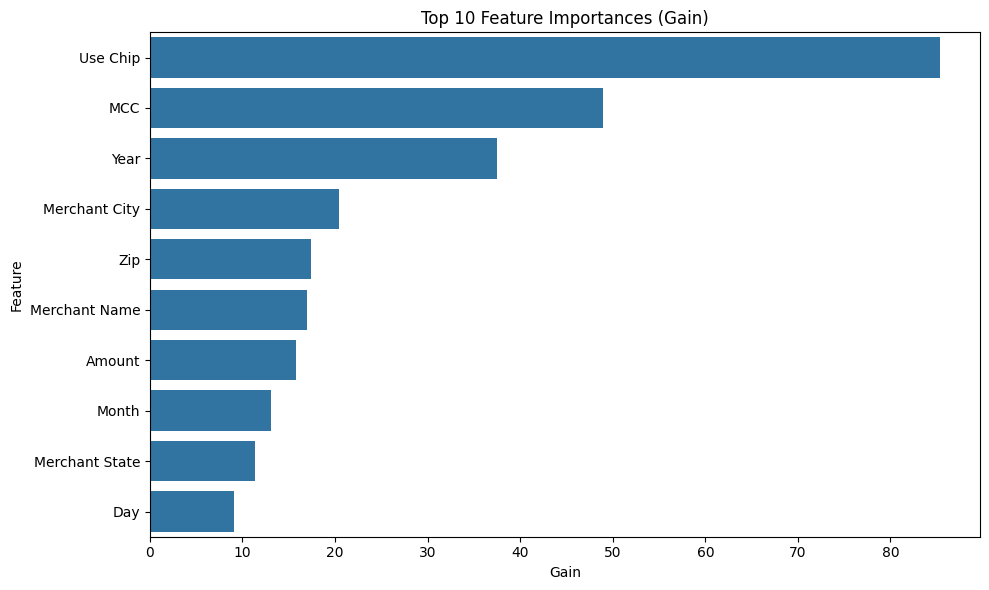

In [ ]:
print("Evaluating on Test Set...")
y_pred_test = xgb_model.predict(dtest)

test_ap = average_precision_score(y_test, y_pred_test)
test_auc = roc_auc_score(y_test, y_pred_test)

print(f"Test AUPRC: {test_ap:.4f}")
print(f"Test AUROC: {test_auc:.4f}")

# Feature importance
importance = xgb_model.get_score(importance_type='gain')
imp_df = pd.DataFrame(list(importance.items()), columns=['Feature', 'Gain'])
imp_df = imp_df.sort_values(by='Gain', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x='Gain', y='Feature', data=imp_df)
plt.title('Top 10 Feature Importances (Gain)')
plt.tight_layout()
# plt.show() # Not showing plot to avoid blocking